# Data Loading and Exploratory Data Analysis

## Importing libraries and loading the dataset

In [ ]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent plotting style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)

# Project directory: assumes the notebook is run from the project root
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "dt_simulated_weekly.csv").exists():
    if (PROJECT_DIR.parent / "data" / "dt_simulated_weekly.csv").exists():
        PROJECT_DIR = PROJECT_DIR.parent

DATA_PATH = PROJECT_DIR / "data" / "dt_simulated_weekly.csv"

# Check that the CSV exists before loading it
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Confirm that dt_simulated_weekly.csv is inside the project's data folder."
    )

In [2]:
# Load the dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print(f"Dataset location: {DATA_PATH}")
print(f"Dataset shape: {df.shape}")

display(df.head())

Dataset loaded successfully!
Dataset location: d:\Neel\Projects for Resume\cpg_marketing_mixed_model\data\dt_simulated_weekly.csv
Dataset shape: (208, 12)


,DATE,revenue,tv_S,ooh_S,print_S,facebook_I,search_clicks_P,search_S,competitor_sales_B,facebook_S,events,newsletter
0,2015-11-23,2.754372e+06,22358.346667,0.0,12728.488889,2.430128e+07,0.000000,0.000000,8125009,7607.132915,na,19401.653846
1,2015-11-30,2.584277e+06,28613.453333,0.0,0.000000,5.527033e+06,9837.238486,4133.333333,7901549,1141.952450,na,14791.000000
2,2015-12-07,2.547387e+06,0.000000,132278.4,453.866667,1.665159e+07,12044.119653,3786.666667,8300197,4256.375378,na,14544.000000
3,2015-12-14,2.875220e+06,83450.306667,0.0,17680.000000,1.054977e+07,12268.070319,4253.333333,8122883,2800.490677,na,2800.000000
4,2015-12-21,2.215953e+06,0.000000,277336.0,0.000000,2.934090e+06,9467.248023,3613.333333,7105985,689.582605,na,15478.000000


## Inspecting structure and data types

In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['DATE', 'revenue', 'tv_S', 'ooh_S', 'print_S', 'facebook_I', 'search_clicks_P', 'search_S', 'competitor_sales_B', 'facebook_S', 'events', 'newsletter']


In [5]:
print("\nData types:")
print(df.dtypes)


Data types:
DATE                      str
revenue               float64
tv_S                  float64
ooh_S                 float64
print_S               float64
facebook_I            float64
search_clicks_P       float64
search_S              float64
competitor_sales_B      int64
facebook_S            float64
events                    str
newsletter            float64
dtype: object


In [6]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   DATE                208 non-null    str    
 1   revenue             208 non-null    float64
 2   tv_S                208 non-null    float64
 3   ooh_S               208 non-null    float64
 4   print_S             208 non-null    float64
 5   facebook_I          208 non-null    float64
 6   search_clicks_P     208 non-null    float64
 7   search_S            208 non-null    float64
 8   competitor_sales_B  208 non-null    int64  
 9   facebook_S          208 non-null    float64
 10  events              208 non-null    str    
 11  newsletter          208 non-null    float64
dtypes: float64(9), int64(1), str(2)
memory usage: 19.6 KB


In [ ]:
print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DATE,208,208,2015-11-23,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue,208.0,NaN,NaN,NaN,1822142.772436,716228.606651,672250.0,1165211.25,1874514.166667,2378407.083333,3827520.0
tv_S,208.0,NaN,NaN,NaN,14843.691218,28558.366546,0.0,0.0,0.0,18406.706667,158046.573333
ooh_S,208.0,NaN,NaN,NaN,43217.941026,83991.426655,0.0,0.0,0.0,50858.133333,500361.6
print_S,208.0,NaN,NaN,NaN,3728.632265,6483.070232,0.0,0.0,0.0,4767.833333,31922.311111
facebook_I,208.0,NaN,NaN,NaN,8153414.998042,11699127.449053,0.0,0.0,0.0,13737419.399594,59432757.638193
search_clicks_P,208.0,NaN,NaN,NaN,16945.206847,13614.093674,0.0,6280.684504,14265.252495,25236.84356,52188.128214
search_S,208.0,NaN,NaN,NaN,5915.512821,4702.502612,0.0,2353.333333,4806.666667,8536.666667,17880.0
competitor_sales_B,208.0,NaN,NaN,NaN,5538024.903846,2077191.970659,2240235.0,3589581.25,5538524.0,7311814.0,9984742.0
facebook_S,208.0,NaN,NaN,NaN,2145.657826,3160.363803,0.0,0.0,0.0,3623.012233,15400.391408


## Cleaning column names and validating dates

In [8]:
# Remove accidental whitespace from column names
df.columns = df.columns.str.strip()

# Convert dates to pandas datetime format
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")

# Sort observations chronologically
df = df.sort_values("DATE").reset_index(drop=True)

# Report date parsing issues
print("Rows:", len(df))
print("Invalid dates:", df["DATE"].isna().sum())
print("Date range:", df["DATE"].min(), "to", df["DATE"].max())

Rows: 208
Invalid dates: 0
Date range: 2015-11-23 00:00:00 to 2019-11-11 00:00:00


In [9]:
# Check duplicate dates and rows
print("Duplicate dates:", df["DATE"].duplicated().sum())
print("Duplicate complete rows:", df.duplicated().sum())

Duplicate dates: 0
Duplicate complete rows: 0


In [10]:
# Check weekly intervals
date_intervals = df["DATE"].diff().dt.days.dropna()

print("\nDate interval distribution (days):")
display(date_intervals.value_counts().sort_index().rename_axis("Days").to_frame("Count"))


Date interval distribution (days):


,Count
Days,
7.0,207


## Checking missing values and invalid values

In [11]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Count"))

Missing values by column:


,Missing Count
DATE,0
revenue,0
tv_S,0
ooh_S,0
print_S,0
facebook_I,0
search_clicks_P,0
search_S,0
competitor_sales_B,0
facebook_S,0


In [12]:
print("\nPercentage of missing values:")
display(
    (df.isnull().mean() * 100)
    .round(2)
    .to_frame("Missing Percentage")
)


Percentage of missing values:


,Missing Percentage
DATE,0.0
revenue,0.0
tv_S,0.0
ooh_S,0.0
print_S,0.0
facebook_I,0.0
search_clicks_P,0.0
search_S,0.0
competitor_sales_B,0.0
facebook_S,0.0


In [13]:
# Target variable checks
print("\nRevenue summary:")
display(df["revenue"].describe())

print("Non-positive revenue:", (df["revenue"] <= 0).sum())


Revenue summary:


count    2.080000e+02
mean     1.822143e+06
std      7.162286e+05
min      6.722500e+05
25%      1.165211e+06
50%      1.874514e+06
75%      2.378407e+06
max      3.827520e+06
Name: revenue, dtype: float64

Non-positive revenue: 0


In [14]:
# Define the initial media spend columns
media_cols = [
    "tv_S",
    "ooh_S",
    "print_S",
    "facebook_S",
    "search_S",
]

# Validate that expected columns exist
missing_media_cols = [col for col in media_cols if col not in df.columns]

if missing_media_cols:
    raise ValueError(f"Expected media columns are missing: {missing_media_cols}")

print("\nMedia spend summary:")
display(df[media_cols].describe().T.round(2))

print("\nNegative media spend values:")
display((df[media_cols] < 0).sum().to_frame("Negative Count"))


Media spend summary:


,count,mean,std,min,25%,50%,75%,max
tv_S,208.0,14843.69,28558.37,0.0,0.00,0.00,18406.71,158046.57
ooh_S,208.0,43217.94,83991.43,0.0,0.00,0.00,50858.13,500361.60
print_S,208.0,3728.63,6483.07,0.0,0.00,0.00,4767.83,31922.31
facebook_S,208.0,2145.66,3160.36,0.0,0.00,0.00,3623.01,15400.39
search_S,208.0,5915.51,4702.50,0.0,2353.33,4806.67,8536.67,17880.00



Negative media spend values:


,Negative Count
tv_S,0
ooh_S,0
print_S,0
facebook_S,0
search_S,0


## Plot weekly revenue

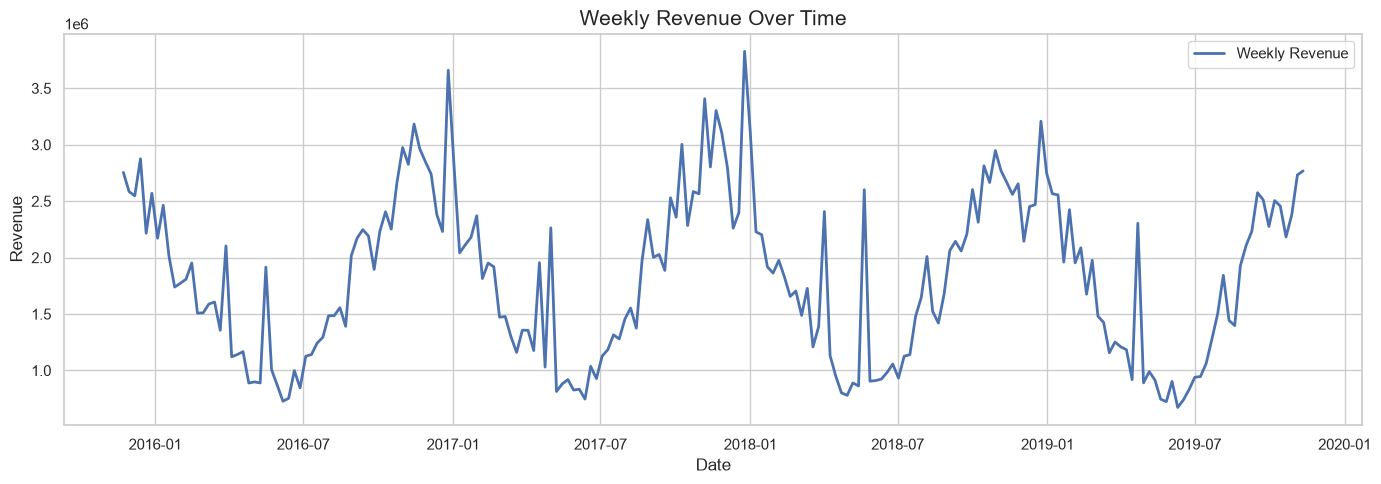

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["DATE"],
    df["revenue"],
    linewidth=2,
    label="Weekly Revenue"
)

plt.title("Weekly Revenue Over Time", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

## Visualize media spend over time

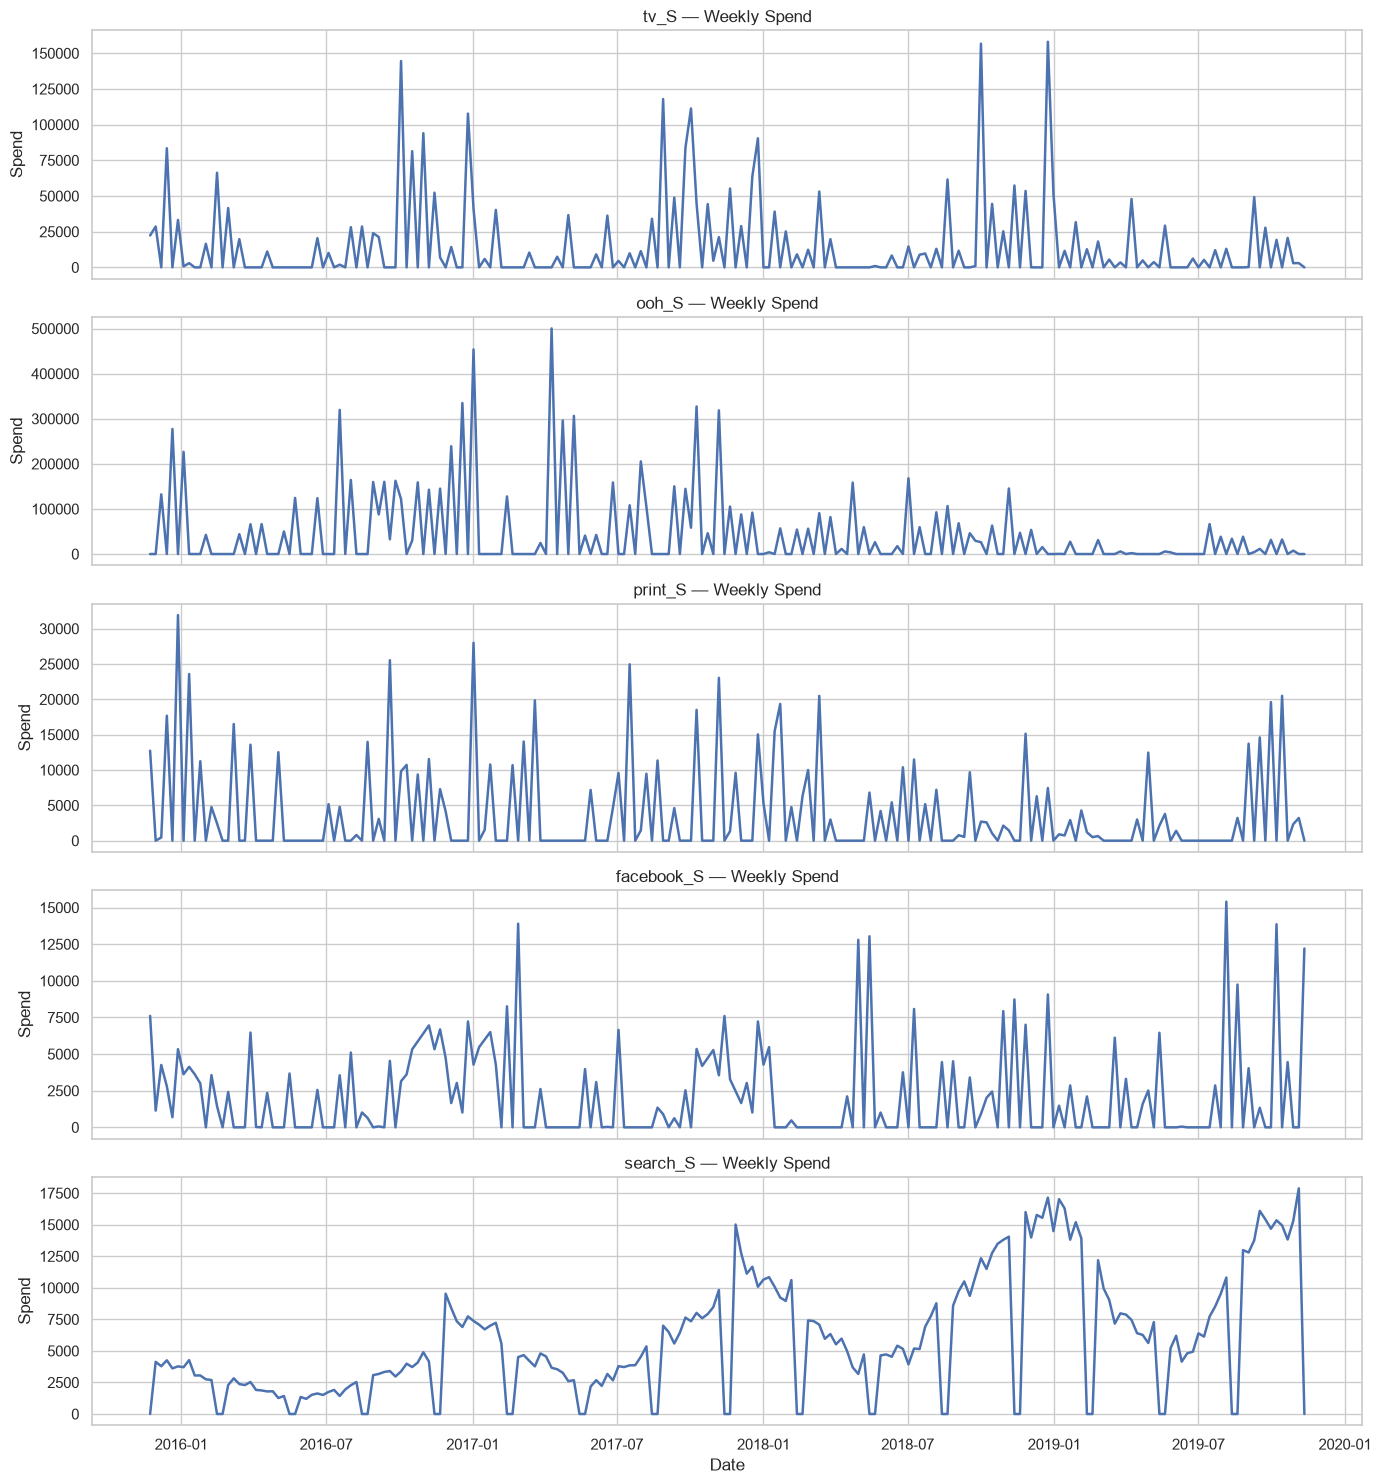

In [16]:
fig, axes = plt.subplots(
    nrows=len(media_cols),
    ncols=1,
    figsize=(14, 3 * len(media_cols)),
    sharex=True
)

for ax, col in zip(axes, media_cols):
    ax.plot(df["DATE"], df[col], linewidth=1.8)
    ax.set_title(f"{col} — Weekly Spend")
    ax.set_ylabel("Spend")

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## Inspect the relation between Revenue and Media

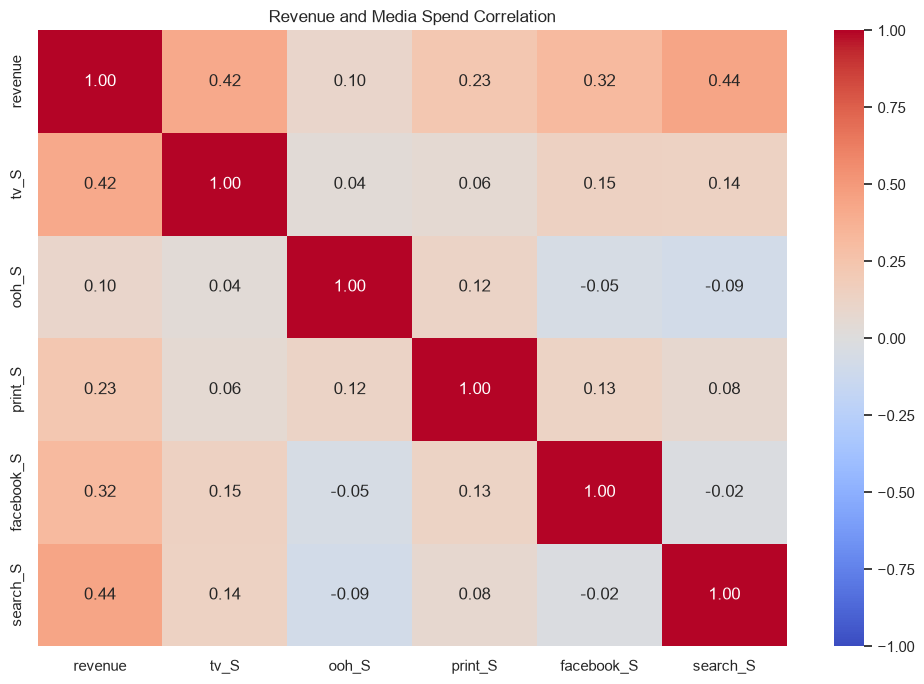

Correlation with revenue:


,Correlation with Revenue
search_S,0.442774
tv_S,0.419869
facebook_S,0.317594
print_S,0.230415
ooh_S,0.095279


In [17]:
correlation_cols = ["revenue"] + media_cols
correlation_matrix = df[correlation_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Revenue and Media Spend Correlation")
plt.tight_layout()
plt.show()

print("Correlation with revenue:")
display(
    correlation_matrix["revenue"]
    .drop("revenue")
    .sort_values(ascending=False)
    .to_frame("Correlation with Revenue")
)

## Check how media channels relate to one another

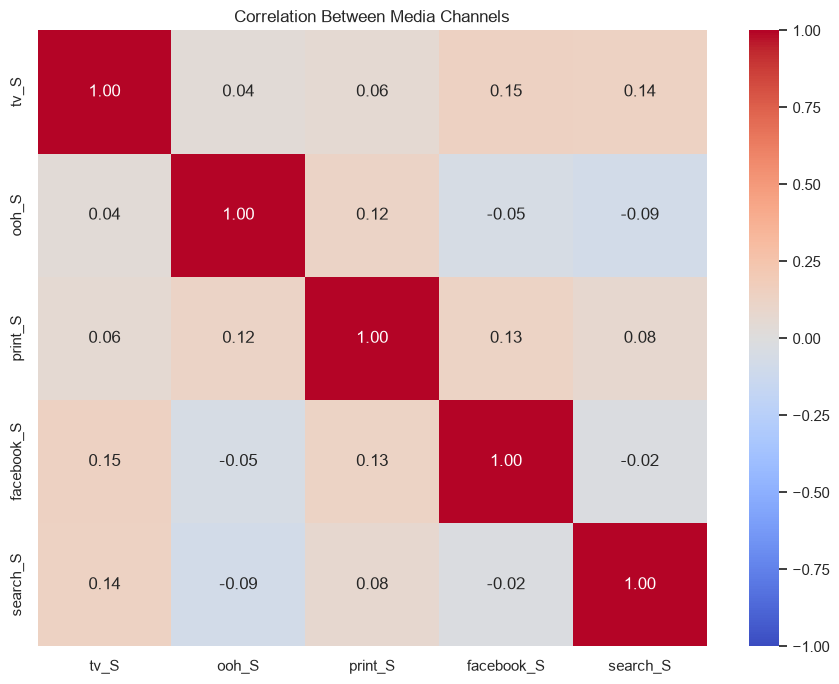

Highly correlated channel pairs (absolute correlation >= 0.70):


In [18]:
# Examine multicollinearity among the five media-spend variables

media_corr = df[media_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    media_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Media Channels")
plt.tight_layout()
plt.show()

print("Highly correlated channel pairs (absolute correlation >= 0.70):")

for i in range(len(media_cols)):
    for j in range(i + 1, len(media_cols)):
        corr = media_corr.iloc[i, j]

        if abs(corr) >= 0.70:
            print(
                f"{media_cols[i]} vs {media_cols[j]}: "
                f"{corr:.3f}"
            )

## Inspecting events and other auxilizary variables

In [19]:
# Inspect non-media variables before deciding how to use them

auxiliary_cols = [
    "competitor_sales_B",
    "events",
    "newsletter",
    "facebook_I",
    "search_clicks_P"
]

for col in auxiliary_cols:
    if col not in df.columns:
        continue

    print(f"\n--- {col} ---")
    print("Data type:", df[col].dtype)
    print("Unique values:", df[col].nunique())
    print("Missing values:", df[col].isna().sum())

    if df[col].dtype == "object":
        display(df[col].value_counts(dropna=False).head(15).to_frame("Count"))
    else:
        display(df[col].describe().to_frame("Statistics"))


--- competitor_sales_B ---
Data type: int64
Unique values: 208
Missing values: 0


,Statistics
count,2.080000e+02
mean,5.538025e+06
std,2.077192e+06
min,2.240235e+06
25%,3.589581e+06
50%,5.538524e+06
75%,7.311814e+06
max,9.984742e+06



--- events ---
Data type: str
Unique values: 3
Missing values: 0


,Statistics
count,208
unique,3
top,na
freq,206



--- newsletter ---
Data type: float64
Unique values: 177
Missing values: 0


,Statistics
count,208.000000
mean,22386.523669
std,19104.164424
min,301.000000
25%,9010.500000
50%,19401.653846
75%,27546.500000
max,96236.000000



--- facebook_I ---
Data type: float64
Unique values: 103
Missing values: 0


,Statistics
count,2.080000e+02
mean,8.153415e+06
std,1.169913e+07
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,1.373742e+07
max,5.943276e+07



--- search_clicks_P ---
Data type: float64
Unique values: 177
Missing values: 0


,Statistics
count,208.000000
mean,16945.206847
std,13614.093674
min,0.000000
25%,6280.684504
50%,14265.252495
75%,25236.843560
max,52188.128214


## Verifying seasonality

,mean,median,std,count
month,,,,
1,2263679.63,2191255.83,350607.93,18
2,1797924.02,1814556.67,185708.54,17
3,1442367.92,1407230.00,239743.05,16
4,1245123.06,1136430.83,482097.43,18
5,1106536.67,894210.00,548119.28,18
6,868191.04,874484.17,118175.76,16
7,1222073.77,1184220.00,198137.84,19
8,1671366.08,1553355.00,289158.10,17
9,2183885.49,2170721.67,203561.86,17


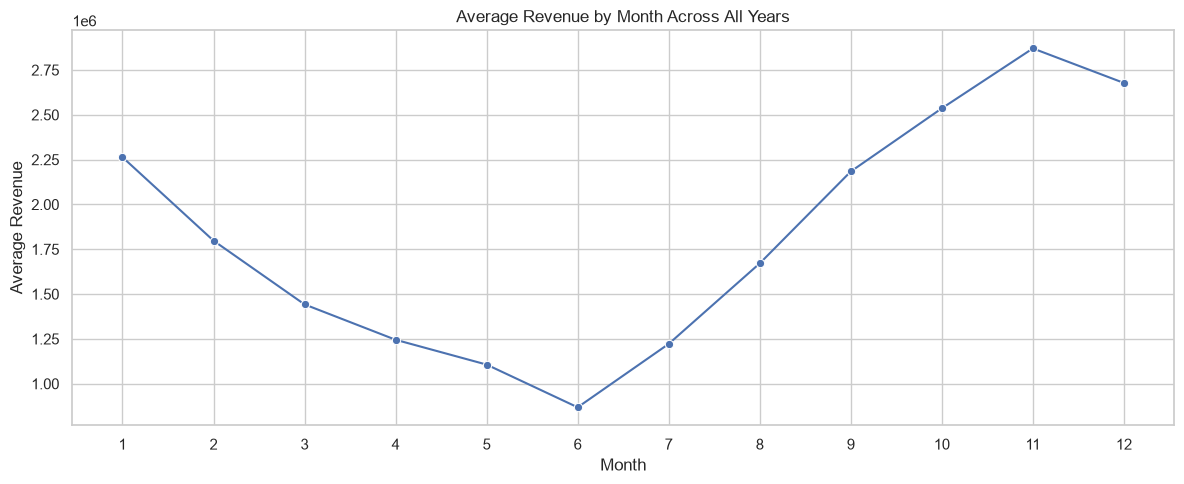

Average revenue by year:


,Average Revenue
year,
2015,2591188.33
2016,1796652.82
2017,1874726.09
2018,1847854.18
2019,1658013.15


In [20]:
df["month"] = df["DATE"].dt.month
df["year"] = df["DATE"].dt.year
df["week_of_year"] = df["DATE"].dt.isocalendar().week.astype(int)

# Revenue distribution by month across all years
monthly_revenue = (
    df.groupby("month")["revenue"]
    .agg(["mean", "median", "std", "count"])
    .round(2)
)

display(monthly_revenue)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=df,
    x="month",
    y="revenue",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Revenue by Month Across All Years")
plt.xlabel("Month")
plt.ylabel("Average Revenue")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Compare average revenue by year
yearly_revenue = df.groupby("year")["revenue"].mean().round(2)
print("Average revenue by year:")
display(yearly_revenue.to_frame("Average Revenue"))

## Inspecting event categories

In [21]:
print("Event category counts:")
display(df["events"].value_counts(dropna=False).to_frame("Count"))

print("\nEvent category percentages:")
display(
    (df["events"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("Percentage")
)

# Inspect rows where an event is recorded
non_na_events = df[
    df["events"].astype(str).str.strip().str.lower() != "na"
]

print("\nRows with a recorded event:", len(non_na_events))
display(non_na_events[["DATE", "revenue", "events"]])

Event category counts:


,Count
events,
na,206
event1,1
event2,1



Event category percentages:


,Percentage
events,
na,99.04
event1,0.48
event2,0.48



Rows with a recorded event: 2


,DATE,revenue,events
130,2018-05-21,2.601602e+06,event1
178,2019-04-22,2.303595e+06,event2


## Saving the validated dataset

In [22]:
from pathlib import Path

# Keep all original columns, including auxiliary variables.
# Do not remove rows or impute values without a specific reason.
df_clean = df.drop(
    columns=["month", "year", "week_of_year"],
    errors="ignore"
).copy()

df_clean = df_clean.sort_values("DATE").reset_index(drop=True)

# Confirm critical data-quality conditions
assert df_clean["DATE"].notna().all(), "Invalid dates remain."
assert df_clean["revenue"].notna().all(), "Missing revenue remains."
assert not df_clean["DATE"].duplicated().any(), "Duplicate dates remain."

# Save to the project's data directory
output_path = PROJECT_DIR / "data" / "mmm_eda_clean.csv"
df_clean.to_csv(output_path, index=False)

print("Preparation complete.")
print("Saved to:", output_path)
print("Final shape:", df_clean.shape)
print("Missing values:", int(df_clean.isna().sum().sum()))
print("Date range:", df_clean["DATE"].min(), "to", df_clean["DATE"].max())

Preparation complete.
Saved to: d:\Neel\Projects for Resume\cpg_marketing_mixed_model\data\mmm_eda_clean.csv
Final shape: (208, 12)
Missing values: 0
Date range: 2015-11-23 00:00:00 to 2019-11-11 00:00:00


## Verify the prepared dataset

In [23]:
from pathlib import Path
import pandas as pd

clean_path = PROJECT_DIR / "data" / "mmm_eda_clean.csv"

assert clean_path.exists(), (
    f"Prepared dataset not found: {clean_path}. "
    "Run Cell 11 first."
)

df_clean = pd.read_csv(clean_path, parse_dates=["DATE"])

print("Prepared dataset loaded successfully.")
print("Shape:", df_clean.shape)
print("Date range:", df_clean["DATE"].min(), "to", df_clean["DATE"].max())
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate dates:", df_clean["DATE"].duplicated().sum())

Prepared dataset loaded successfully.
Shape: (208, 12)
Date range: 2015-11-23 00:00:00 to 2019-11-11 00:00:00
Missing values: 0
Duplicate dates: 0



### Stage 1: Data Acquisition, Exploratory Data Analysis, and Preparation

1. Loaded the Robyn simulated weekly marketing dataset containing **208 observations and 12 columns**, covering November 23, 2015, to November 11, 2019. Parsed the date column and verified that the dataset had no missing values, duplicate dates, duplicate complete rows, or irregular weekly intervals.

2. Explored revenue, media spending, marketing activity, and control variables. Observed a strong seasonal-looking revenue pattern, with average revenue highest in November and lowest in June. Raw correlations with revenue were strongest for Search spend (0.443), TV spend (0.420), and Facebook spend (0.318); these correlations are descriptive and do not establish causality.

3. Validated the five media-spend variables—TV, OOH, Print, Facebook, and Search—and confirmed that none contained negative values. Saved the cleaned dataset as `data/mmm_eda_clean.csv` for use in subsequent modeling stages. The source data is simulated, so results should not be interpreted as evidence of real-world marketing effectiveness.
